In [1]:
import numpy as np
import pandas as pd
import scipy.optimize
import matplotlib.pyplot as plt
import math
import pyperclip
import os
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.stats import norm

# Def Functions

In [2]:
def divergence_fitting(file_folder, file_name, offset = False, error="STD", plot = True, distancenozzle = 2.46):
    # ── INPUTS ────────────────────────────────────────────────────────────────────
    filepath3      = os.path.join(file_folder, file_name)
    nozzleheight   = 0.150             # nozzle height in, 
    nozzleheight   = 0.1               # nozzle diameter in, this seems to be correct....
    # distancenozzle in in
    # near = 2.46
    # far = 12.3
    unit_conv      = 39.3701              # unit conversion factor applied to x-axis
    # ──────────────────────────────────────────────────────────────────────────────

    # load results CSV
    df = pd.read_csv(filepath3)

    # compute mean and std error across sides for plotting
    x_full = df['height']
    scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()
    y_full = np.mean(scales, axis=1)
    if error == "STD":
        y_err  = np.std(scales, axis=1, ddof=1)
    elif error == "SEM":
        y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])

    # fit gaussian
    if offset:
        p0_gaussian    = [0.05, 400, 100, 0.0]  # initial guess: [amplitude, center, sigma, offset]
        def gaussian(x, A, x0, sigma, offset):
            return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset
    else:          
        p0_gaussian    = [0.05, 400, 100]  # initial guess: [amplitude, center, sigma, offset]
        def gaussian(x, A, x0, sigma):
            return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2))

    y_err_fit = np.where(y_err > 0, y_err, np.finfo(float).eps) #prevent divide be zero error, sometimes happens

    popt, pcov = curve_fit(
        gaussian, x_full, y_full,
        p0=p0_gaussian,
        sigma=y_err_fit,
        absolute_sigma=True
    )

    # ── Extract fit parameters and widths ─────────────────────────────────────────
    sigma     = popt[2]
    sigma_err = np.sqrt(pcov[2, 2])
    dx        = popt[1]

    FWHM      = 2 * np.sqrt(2 * np.log(2)) * sigma
    width_1e  = 2 * np.sqrt(2) * sigma

    FWHM_err     = 2 * np.sqrt(2 * np.log(2)) * sigma_err
    width_1e_err = 2 * np.sqrt(2) * sigma_err

    # ── Reduced chi-squared & R² ──────────────────────────────────────────────────
    fit = gaussian(x_full, *popt)
    residuals = (y_full - fit)
    dof = len(y_full) - len(popt)
    chi2_reduced = np.sum((residuals/y_err)**2)/dof

    ss_res = np.sum(residuals ** 2)
    ss_tot = np.sum((y_full - np.mean(y_full)) ** 2)
    r_squared = 1 - ss_res / ss_tot

    # ── Divergence half-angle — 1/e width ─────────────────────────────────────────
    beamgrowth = width_1e / 1000 - nozzleheight # in

    du_dw      = 1.0 / (2 * 1000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_1e     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_1e_err = abs(dtheta_dw) * width_1e_err

    # ── Divergence half-angle — FWHM ──────────────────────────────────────────────
    beamgrowth = FWHM / 1000 - nozzleheight

    du_dw      = 1.0 / (2000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_FWHM     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_FWHM_err = abs(dtheta_dw) * FWHM_err

    # convert thou in to mm
    FWHM = FWHM/unit_conv
    FWHM_err = FWHM_err/unit_conv
    width_1e = width_1e/unit_conv
    width_1e_err = width_1e_err/unit_conv

    if plot:
        # ── Plot + results table ───────────────────────────────────────────────────────
        x_fit = np.linspace(0, 1000, 2000)
        y_fit = gaussian(x_fit, *popt)

        fig, (ax_plot, ax_table) = plt.subplots(1, 2, figsize=(10, 5),
                                                gridspec_kw={'width_ratios': [2, 1]})
        fig.suptitle(file_name, fontsize=9, color='gray')

        ax_plot.errorbar((x_full - popt[1]) / unit_conv, y_full, yerr=y_err,
                        fmt='x', markersize=3, linestyle='None', capsize=2, c="blue",label='Data')
        ax_plot.plot((x_fit - popt[1]) / unit_conv, y_fit, c="blue", alpha=0.8, linewidth=1.5,label="Gaussian fit")
        ax_plot.set_xlabel(r'$\Delta y$ [mm]',fontsize=16)
        ax_plot.set_ylabel("Relative Absorption [Arb. Units]",fontsize=16)
        ax_plot.tick_params(axis='both', labelsize=12)
        ax_plot.legend()

        # table of key results
        table_data = [
            ["Reduced χ²",        f"{chi2_reduced:.4f}"],
            ["R²",                f"{r_squared:.4f}"],
            ["FWHM (mm)",              f"{FWHM:.2f} ± {FWHM_err:.2f}"],
            ["θ½ (FWHM) [deg]",   f"{divhalfangle_FWHM*180/math.pi:.3f} ± {divhalfangle_FWHM_err*180/math.pi:.3f}"],
            ["1/e width (mm)",         f"{width_1e:.2f} ± {width_1e_err:.2f}"],
            ["θ½ (1/e) [deg]",    f"{divhalfangle_1e*180/math.pi:.3f} ± {divhalfangle_1e_err*180/math.pi:.3f}"],
        ]

        settings_data = [
            ["Offset", str(offset)],
            ["Error",  error],
        ]

        ax_table.axis('off')
        tbl = ax_table.table(cellText=table_data, colLabels=["Parameter", "Value"],
                            loc='center', cellLoc='left')
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(10)
        tbl.scale(1, 2)

        tbl2 = ax_table.table(cellText=settings_data, colLabels=["Setting", "Value"],
                            loc='lower center', cellLoc='left')
        tbl2.auto_set_font_size(False)
        tbl2.set_fontsize(9)
        tbl2.scale(1, 1.5)

        plt.tight_layout()
        plt.show()
    
    # put results in dict
    results = {
        "FWHM":               FWHM,
        "FWHM_err":           FWHM_err,
        "width_1e":           width_1e,
        "width_1e_err":       width_1e_err,
        "divhalfangle_FWHM":  divhalfangle_FWHM * 180 / math.pi,
        "divhalfangle_FWHM_err": divhalfangle_FWHM_err * 180 / math.pi,
        "divhalfangle_1e":    divhalfangle_1e * 180 / math.pi,
        "divhalfangle_1e_err": divhalfangle_1e_err * 180 / math.pi,
        "chi2_reduced":       chi2_reduced,
        "r_squared":          r_squared,
        "x_full":             x_full.to_numpy(),
        "y_full":             y_full,
        "y_err":              y_err,
        "popt":               popt,
        "pcov":               pcov,
    }
    
    return results

In [3]:
def flux_from_divergence(flux_file, div_results, center_x_thou, T_oven_C=230, plot=True):
    """
    Compute total Rb beam flux....

    """
    # ── Constants ─────────────────────────────────────────────────────────────
    sigma_eff = 1.246e-9                         # cm² (isotropic pol, 85Rb D2 F3→F'4)
    fF3       = 7 / 12                           # thermal population fraction in F=3
    PRb85     = 0.7217                           # 85Rb isotopic abundance
    kB        = 1.380649e-23                     # J/K
    m_rb      = 85.4678 * 1.66053906660e-27      # kg
    unit_conv = 39.3701                          # thou-in per mm
    
    T_K = 273.15 + T_oven_C

    # ── 1. Column density from absolute absorption ────────────────────────────
    df_flux     = pd.read_csv(flux_file)
    absorptions = np.concatenate([df_flux[f'Scale{i}'].to_numpy() for i in range(1, 5)])
    abs_mean    = absorptions.mean()

    T0    = 1 - abs_mean / 100 
    print(f"abs_mean = {abs_mean/100}")
    OD0   = -math.log(T0)
    print(f"OD = {OD0}")
    nRb85 = OD0 / (sigma_eff * fF3)       # cm⁻²
    nRb   = nRb85 / PRb85                 # cm⁻²

    # ── 2. Rescale divergence Gaussian to column density ──────────────────────
    y_full = div_results['y_full']
    y_err  = div_results['y_err']
    popt   = div_results['popt']
    x0     = popt[1]

    x_full  = div_results['x_full']
    closest_idx = np.argmin(np.abs(x_full - center_x_thou))
    rescale = nRb / y_full[closest_idx]

    def gaussian(x, A, x0, sigma):
        return A * np.exp(-(x - x0)**2 / (2.0 * sigma**2))

    x_fit_thou = np.linspace(0, 1000, 2000)
    y_fit      = rescale * gaussian(x_fit_thou, *popt[:3])

    # ── 3. Integrate column density across beam ───────────────────────────────
    x_fit_cm        = np.linspace(0, 2.54, 2000)
    N_cross_section = np.trapezoid(y_fit, x_fit_cm)   # cm⁻¹

    # ── 4. Mean speed → flux ──────────────────────────────────────────────────
    v_mean = math.sqrt(8 * kB * T_K / (math.pi * m_rb)) * 100   # cm/s
    Rb_flux = N_cross_section * v_mean                            # atoms/s

    # ── 5. Volume density for reference ───────────────────────────────────────
    interaction_len_cm = div_results['width_1e'] / 10   # mm → cm
    number_density_cm  = nRb / interaction_len_cm        # cm⁻³

    # ── plot ──────────────────────────────────────────────────────────────────
    if plot:
        x_fit_thou = np.linspace(0, 1000, 2000)
        y_fit_scaled = rescale * gaussian(x_fit_thou, *popt[:3])

        fig, (ax_plot, ax_table) = plt.subplots(1, 2, figsize=(10, 5),
                                                 gridspec_kw={'width_ratios': [2, 1]})
        fig.suptitle(flux_file, fontsize=9, color='gray')

        x_full = div_results['x_full']
        ax_plot.errorbar((x_full - x0) / unit_conv, rescale * y_full, yerr=rescale * y_err,
                         fmt='x', markersize=3, linestyle='None', capsize=2, c="blue", label='Data')
        ax_plot.plot((x_fit_thou - x0) / unit_conv, y_fit_scaled, c="blue", alpha=0.8,
                     linewidth=1.5, label='Gaussian fit')
        ax_plot.set_xlabel(r'$\Delta y$ [mm]', fontsize=16)
        ax_plot.set_ylabel(r'Rb Density [cm$^{-2}$]', fontsize=16)
        ax_plot.tick_params(axis='both', labelsize=12)
        ax_plot.legend()

        table_data = [
            ["Flux [atoms/s]",       f"{Rb_flux:.1e}"],
            ["n [cm⁻³]",             f"{number_density_cm:.1e}"],
            #["θ½ (FWHM) [deg]",      f"{div_results['divhalfangle_FWHM']:.2f} ± {div_results['divhalfangle_FWHM_err']:.2f}"],
            ["θ½ (1/e) [deg]",       f"{div_results['divhalfangle_1e']:.2f} ± {div_results['divhalfangle_1e_err']:.2f}"],
            #["FWHM [mm]",            f"{div_results['FWHM']:.2f} ± {div_results['FWHM_err']:.2f}"],
            #["1/e width [mm]",       f"{div_results['width_1e']:.2f} ± {div_results['width_1e_err']:.2f}"],
        ]

        settings_data = [
            ["T oven [°C]", str(T_oven_C)],
        ]

        ax_table.axis('off')
        tbl = ax_table.table(cellText=table_data, colLabels=["Parameter", "Value"],
                             loc='center', cellLoc='left')
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(10)
        tbl.scale(1, 2)

        tbl2 = ax_table.table(cellText=settings_data, colLabels=["Setting", "Value"],
                              loc='lower center', cellLoc='left')
        tbl2.auto_set_font_size(False)
        tbl2.set_fontsize(9)
        tbl2.scale(1, 1.5)

        plt.tight_layout()
        plt.show()

    results = {
        "abs_mean_pct":        abs_mean,
        "OD":                  OD0,
        "nRb_column_cm2":      nRb,
        "N_cross_section_cm":  N_cross_section,
        "v_mean_cm_s":         v_mean,
        "Rb_flux_atoms_s":     Rb_flux,
        "number_density_cm3":  number_density_cm,
        "number_density_m3":   number_density_cm * 1e6,
        "rescale_factor":      rescale,
    }

    return results

In [4]:
def dopant_density(Ar_flow_sccm, Rb_flux, Ar_density_crystal = 1768):

    # ── Constants ─────────────────────────────────────────────────────────────
    Na    = 6.02214076e23          # mol⁻¹ Avogadro Constant
    R     = 8.3145                 # J/(mol·K)
    Z     = 0.99906                # compressibility factor for Ar at STP
    P     = 101325.0               # Pa (1 atm)
    M_Ar  = 39.948e-3              # kg/mol
    T_k   = 273.15                 # K (standard conditions)

    Ar_flow_scms = Ar_flow_sccm * 1e-6/60 # cm^3/min -> m^3/s

    # mass flow rate [kg/s] = volumetric * rho = volumetric * P*M / (Z*R*T)
    mass_flow = Ar_flow_scms * (P * M_Ar) / (Z * R * T_k)
    mass_flow_g_hr = mass_flow * 1000 * 3600  # kg/s → g/hr

    # atom flux [atoms/s]
    Ar_flux = mass_flow / M_Ar * Na 

    # ── Dopant Density ──────────────────────────────────────────────────────────
    Rb_per_Ar = Rb_flux / Ar_flux
    Ar_molar_density_crystal = Ar_density_crystal / M_Ar # mol/m^3

    # get num Ar atoms in cubic cm
    Ar_number_per_cm = Ar_molar_density_crystal * Na * 1e-6 # atoms/cm^3
    # get num Rb atoms per cubic cm Ar crystal
    Rb_density = Rb_per_Ar * Ar_number_per_cm # atoms/cm^3

    return Ar_flux, Rb_density, mass_flow_g_hr

In [5]:
def capture_efficiency(
    div_deg,
    div_deg_err,
    z_thou,
    z_thou_err,
    distance_nozzle_to_z1=2.46,        # in — where divergence/width were measured
    distance_nozzle_to_gr=19.685,       # in — growth substrate location
    aperture_radius_cm=0.5,                    # cm — half-width of capture aperture ±aperture_cm
    plot=True,
): # ASSUME THIS IS WRONG UNTIL I CHECK/REDO MYSELF!!!!
    """
    Compute beam capture efficiency at the growth substrate.

    Parameters
    ----------
    div_deg              : float — 1/e half-angle divergence [degrees]
    div_deg_err          : float — uncertainty in div_deg [degrees]
    z_thou               : float — 1/e full beam width at zone 1 [thou]
    z_thou_err           : float — uncertainty in z_thou [thou]
    distance_nozzle_to_z1: float — nozzle→measurement point [in] (default 2.46)
    distance_nozzle_to_gr: float — nozzle→growth substrate [in] (default 19.685)
    aperture_cm          : float — capture half-width [cm] (default 0.5)
    plot                 : bool  — show diagnostic plot
    """
    # ── Constants ─────────────────────────────────────────────────────────────
    thou_to_cm = 2.54 / 1000.0          # 1 thou = 0.001 in = 0.00254 cm
    in_to_cm   = 2.54                   # 1 in = 2.54 cm

    # ── Geometry ──────────────────────────────────────────────────────────────
    # extra distance the beam travels beyond the measurement point [in]
    D_in  = distance_nozzle_to_gr - distance_nozzle_to_z1   # in
    D_cm  = D_in * in_to_cm                                  # cm

    theta = math.radians(div_deg)

    # ── Beam 1/e full-width at growth substrate ───────────────────────────────
    # start from measured full-width at z1 (thou → cm),
    # add growth on each side: half-width grows by D*tan(theta) per side → full-width grows by 2*D*tan(theta)
    z_cm  = z_thou * thou_to_cm                              # measured full-width in cm
    g_1e  = z_cm + 2 * D_cm * math.tan(theta)               # full 1/e width at substrate [cm]
    sigma = g_1e / (2 * math.sqrt(2))                        # Gaussian sigma [cm]

    # ── Propagate uncertainty ─────────────────────────────────────────────────
    dg_dz        = thou_to_cm                                           # ∂g/∂z [cm/thou]
    dg_ddiv_deg  = 2 * D_cm / math.cos(theta)**2 * (math.pi / 180.0)  # ∂g/∂θ [cm/deg]

    dsigma_dz    = dg_dz       / (2 * math.sqrt(2))
    dsigma_ddiv  = dg_ddiv_deg / (2 * math.sqrt(2))

    sigma_err = math.sqrt((dsigma_dz * z_thou_err)**2 + (dsigma_ddiv * div_deg_err)**2)
    g_1e_err  = sigma_err * (2 * math.sqrt(2))

    # ── Capture probability P(|X| ≤ aperture_cm) ─────────────────────────────
    a = aperture_radius_cm
    P = norm.cdf(a, 0, sigma) - norm.cdf(-a, 0, sigma)

    # dP/dσ (analytic)
    t         = a / sigma
    phi       = math.exp(-0.5 * t**2) / math.sqrt(2 * math.pi)
    dP_dsigma = -2 * a * phi / sigma**2
    P_err     = abs(dP_dsigma) * sigma_err

    # ── Plot ──────────────────────────────────────────────────────────────────
    if plot:
        x = np.linspace(-4 * sigma, 4 * sigma, 1000)
        f = norm.pdf(x, 0, sigma)

        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(x, f, color='blue', linewidth=1.5, label='Beam profile')
        ax.axvspan(-a, a, alpha=0.2, color='green', label=f'Aperture ±{a} cm  (P = {P*100:.1f} ± {P_err*100:.1f}%)')
        ax.set_xlabel('Position [cm]', fontsize=14)
        ax.set_ylabel('Probability Density', fontsize=14)
        ax.tick_params(axis='both', labelsize=11)
        ax.legend()
        plt.tight_layout()
        plt.show()

    return {
        "g_1e":      g_1e,
        "g_1e_err":  g_1e_err,
        "sigma":     sigma,
        "sigma_err": sigma_err,
        "P":         P,
        "P_err":     P_err,
    }

# Flux

In [8]:
def capture_efficiency_FWHM(
    div_deg,
    div_deg_err,
    z_thou,
    z_thou_err,
    distance_nozzle_to_z1=2.46,        # in — where divergence/width were measured
    distance_nozzle_to_gr=19.685,       # in — growth substrate location
    aperture_radius_cm=0.5,                    # cm — half-width of capture aperture ±aperture_cm
    plot=True,
): # ASSUME THIS IS WRONG UNTIL I CHECK/REDO MYSELF!!!!
    """
    Compute beam capture efficiency at the growth substrate.

    Parameters
    ----------
    div_deg              : float — 1/e half-angle divergence [degrees]
    div_deg_err          : float — uncertainty in div_deg [degrees]
    z_thou               : float — 1/e full beam width at zone 1 [thou]
    z_thou_err           : float — uncertainty in z_thou [thou]
    distance_nozzle_to_z1: float — nozzle→measurement point [in] (default 2.46)
    distance_nozzle_to_gr: float — nozzle→growth substrate [in] (default 19.685)
    aperture_cm          : float — capture half-width [cm] (default 0.5)
    plot                 : bool  — show diagnostic plot
    """
    # ── Constants ─────────────────────────────────────────────────────────────
    thou_to_cm = 2.54 / 1000.0          # 1 thou = 0.001 in = 0.00254 cm
    in_to_cm   = 2.54                   # 1 in = 2.54 cm

    # ── Geometry ──────────────────────────────────────────────────────────────
    # extra distance the beam travels beyond the measurement point [in]
    D_in  = distance_nozzle_to_gr - distance_nozzle_to_z1   # in
    D_cm  = D_in * in_to_cm                                  # cm

    theta = math.radians(div_deg)

    # ── Beam 1/e full-width at growth substrate ───────────────────────────────
    # start from measured full-width at z1 (thou → cm),
    # add growth on each side: half-width grows by D*tan(theta) per side → full-width grows by 2*D*tan(theta)
    z_cm  = z_thou * thou_to_cm                              # measured full-width in cm
    g_1e  = z_cm + 2 * D_cm * math.tan(theta)               # full 1/e width at substrate [cm]
    sigma = g_1e  / (2 * 2 * math.sqrt(2 * math.log(2)))                      # Gaussian sigma [cm]

    # ── Propagate uncertainty ─────────────────────────────────────────────────
    dg_dz        = thou_to_cm                                           # ∂g/∂z [cm/thou]
    dg_ddiv_deg  = 2 * D_cm / math.cos(theta)**2 * (math.pi / 180.0)  # ∂g/∂θ [cm/deg]

    dsigma_dz    = dg_dz       / (2 * math.sqrt(2))
    dsigma_ddiv  = dg_ddiv_deg / (2 * math.sqrt(2))

    sigma_err = math.sqrt((dsigma_dz * z_thou_err)**2 + (dsigma_ddiv * div_deg_err)**2)
    g_1e_err  = sigma_err * (2 * math.sqrt(2))

    # ── Capture probability P(|X| ≤ aperture_cm) ─────────────────────────────
    a = aperture_radius_cm
    P = norm.cdf(a, 0, sigma) - norm.cdf(-a, 0, sigma)

    # dP/dσ (analytic)
    t         = a / sigma
    phi       = math.exp(-0.5 * t**2) / math.sqrt(2 * math.pi)
    dP_dsigma = -2 * a * phi / sigma**2
    P_err     = abs(dP_dsigma) * sigma_err

    # ── Plot ──────────────────────────────────────────────────────────────────
    if plot:
        x = np.linspace(-4 * sigma, 4 * sigma, 1000)
        f = norm.pdf(x, 0, sigma)

        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(x, f, color='blue', linewidth=1.5, label='Beam profile')
        ax.axvspan(-a, a, alpha=0.2, color='green', label=f'Aperture ±{a} cm  (P = {P*100:.1f} ± {P_err*100:.1f}%)')
        ax.set_xlabel('Position [cm]', fontsize=14)
        ax.set_ylabel('Probability Density', fontsize=14)
        ax.tick_params(axis='both', labelsize=11)
        ax.legend()
        plt.tight_layout()
        plt.show()

    return {
        "g_1e":      g_1e,
        "g_1e_err":  g_1e_err,
        "sigma":     sigma,
        "sigma_err": sigma_err,
        "P":         P,
        "P_err":     P_err,
    }

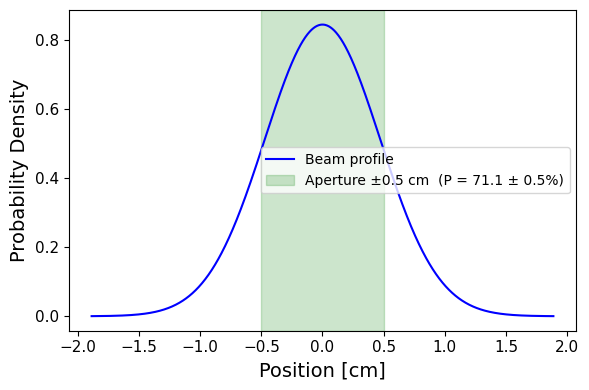

In [11]:
cap_results = capture_efficiency(div_deg= 0.75,div_deg_err=0.01,z_thou = 150,z_thou_err  = 1, distance_nozzle_to_gr=16.8,   aperture_radius_cm=0.5,   plot=True,)

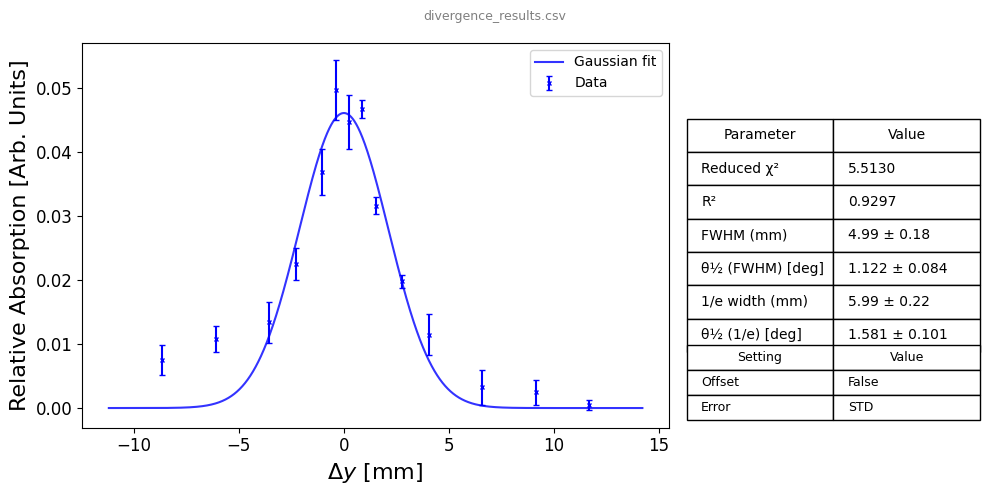

abs_mean = 0.0006685019376792624
OD = 0.0006687254847329628


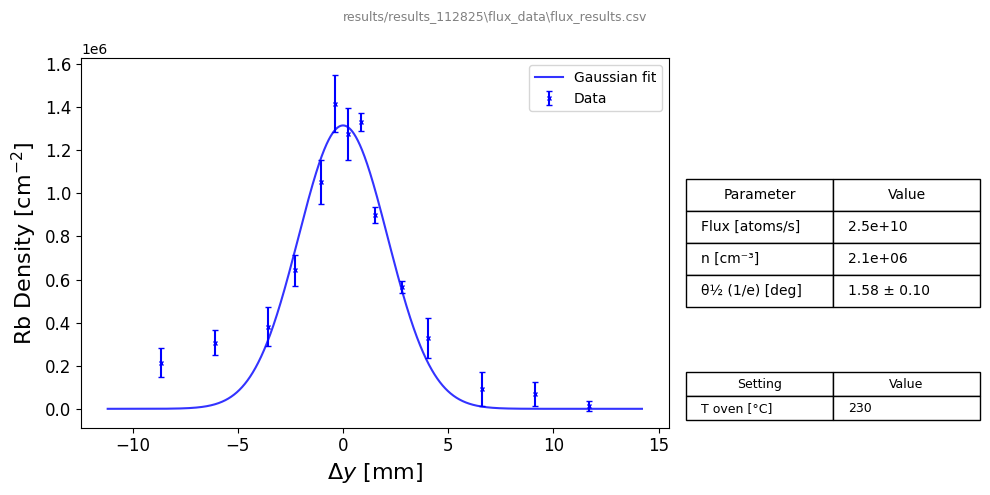

Ar Flux [atoms/s]:              4.48e+15
Ar Flow [g/h]:                  0.0011
Rb Dopant Density [atoms/cm^3]: 1.47e+17


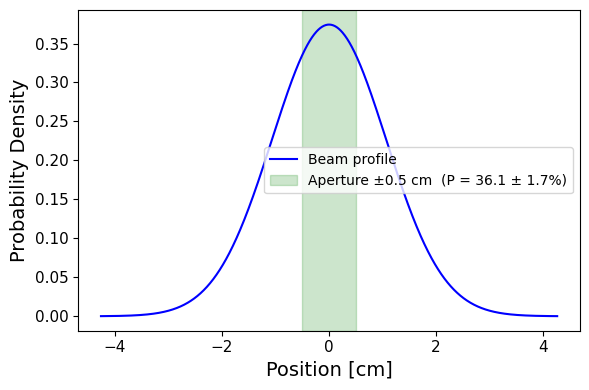

Capture Efficiency:             36.1 ± 1.7 %


In [6]:
results_folder = "results/results_112825"

# get divergence 
div_results = divergence_fitting(results_folder, "divergence_results.csv", offset= False, error="STD", plot=True)

# get Rb flux
flux_file = os.path.join(results_folder, "flux_data", "flux_results.csv")
flux_results = flux_from_divergence(flux_file, div_results, center_x_thou=450, T_oven_C= 230, plot= True)

# get dopant density
Ar_flux, Rb_dopant_density, mass_flow_g_hr = dopant_density(Ar_flow_sccm=0.01, Rb_flux=flux_results["Rb_flux_atoms_s"])

print(f"Ar Flux [atoms/s]:              {Ar_flux:.2e}")
print(f"Ar Flow [g/h]:                  {mass_flow_g_hr:.4f}")
print(f"Rb Dopant Density [atoms/cm^3]: {Rb_dopant_density:.2e}")

cap_results = capture_efficiency(div_deg     = div_results["divhalfangle_1e"],div_deg_err = div_results["divhalfangle_1e_err"],z_thou      = div_results["width_1e"] * 39.3701,z_thou_err  = div_results["width_1e_err"] * 39.3701,distance_nozzle_to_gr=19.685,   aperture_radius_cm=0.5,   plot=True,)
print(f"Capture Efficiency:             {cap_results['P']*100:.1f} ± {cap_results['P_err']*100:.1f} %")


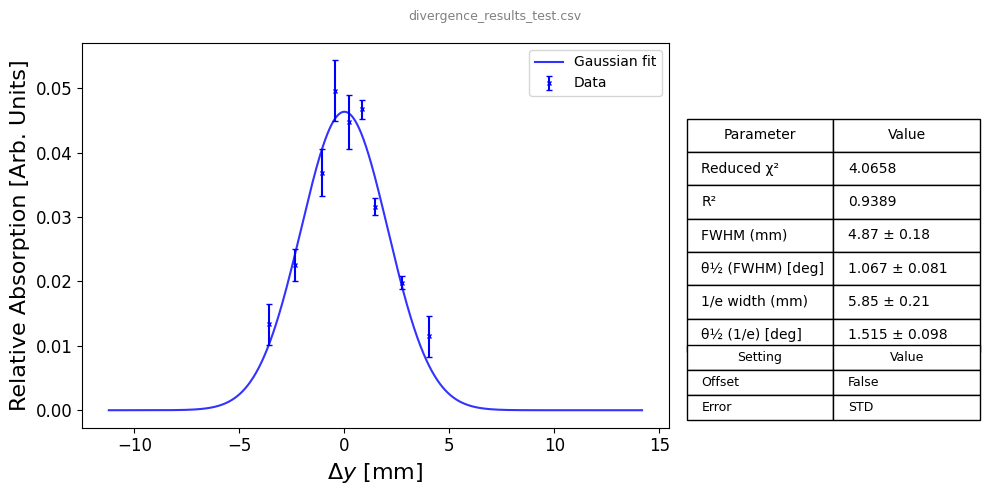

abs_mean = 0.0006685019376792624
OD = 0.0006687254847329628


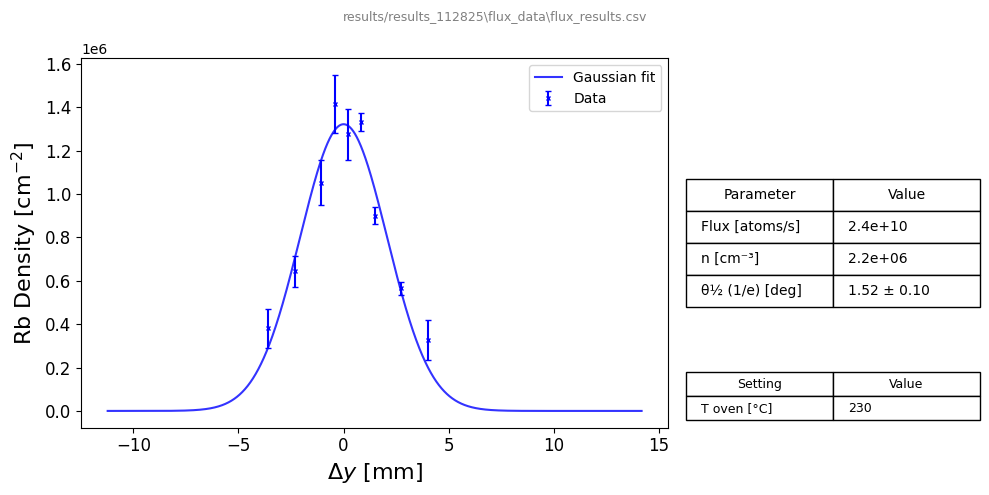

Ar Flux [atoms/s]:              4.48e+15
Ar Flow [g/h]:                  0.0011
Rb Dopant Density [atoms/cm^3]: 1.44e+17


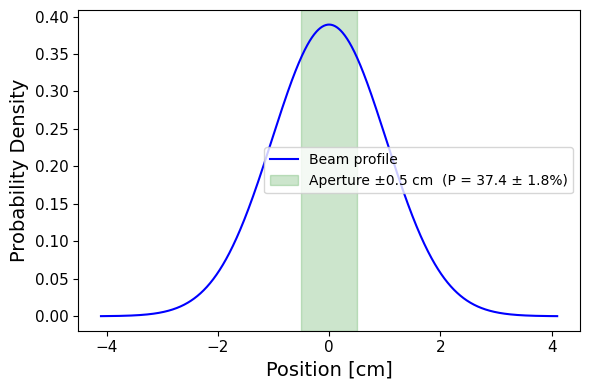

Capture Efficiency:             37.4 ± 1.8 %


In [7]:
results_folder = "results/results_112825"

# get divergence 
div_results = divergence_fitting(results_folder, "divergence_results_test.csv", offset= False, error="STD", plot=True)

# get Rb flux
flux_file = os.path.join(results_folder, "flux_data", "flux_results.csv")
flux_results = flux_from_divergence(flux_file, div_results, center_x_thou=450, T_oven_C= 230, plot= True)

# get dopant density
Ar_flux, Rb_dopant_density, mass_flow_g_hr = dopant_density(Ar_flow_sccm=0.01, Rb_flux=flux_results["Rb_flux_atoms_s"])

print(f"Ar Flux [atoms/s]:              {Ar_flux:.2e}")
print(f"Ar Flow [g/h]:                  {mass_flow_g_hr:.4f}")
print(f"Rb Dopant Density [atoms/cm^3]: {Rb_dopant_density:.2e}")

cap_results = capture_efficiency(div_deg     = div_results["divhalfangle_1e"],div_deg_err = div_results["divhalfangle_1e_err"],z_thou      = div_results["width_1e"] * 39.3701,z_thou_err  = div_results["width_1e_err"] * 39.3701,distance_nozzle_to_gr=19.685,   aperture_radius_cm=0.5,   plot=True,)
print(f"Capture Efficiency:             {cap_results['P']*100:.1f} ± {cap_results['P_err']*100:.1f} %")

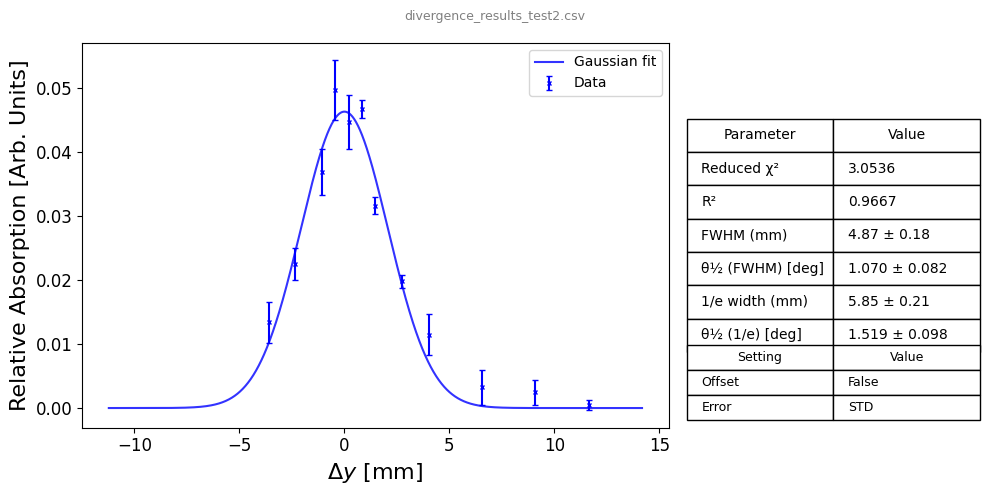

abs_mean = 0.0006685019376792624
OD = 0.0006687254847329628


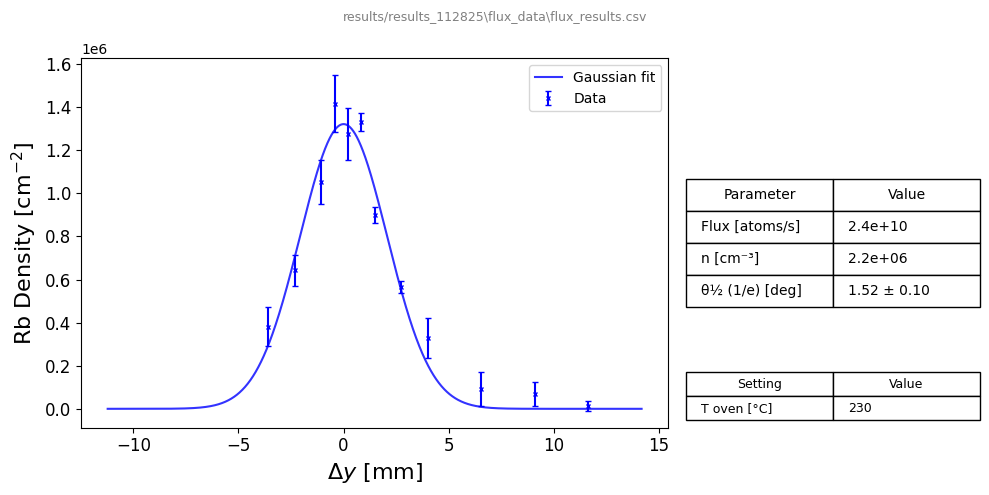

Ar Flux [atoms/s]:              4.48e+15
Ar Flow [g/h]:                  0.0011
Rb Dopant Density [atoms/cm^3]: 1.44e+17


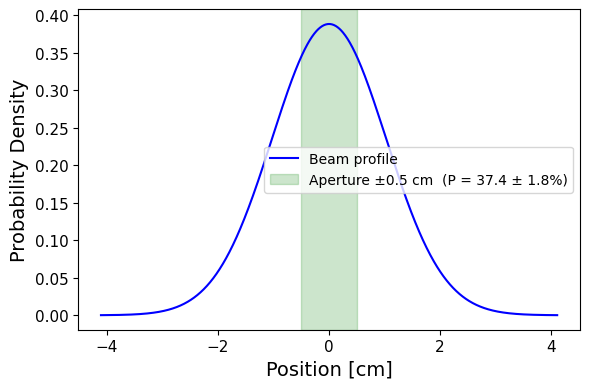

Capture Efficiency:             37.4 ± 1.8 %


In [8]:
results_folder = "results/results_112825"

# get divergence 
div_results = divergence_fitting(results_folder, "divergence_results_test2.csv", offset= False, error="STD", plot=True)

# get Rb flux
flux_file = os.path.join(results_folder, "flux_data", "flux_results.csv")
flux_results = flux_from_divergence(flux_file, div_results, center_x_thou=450, T_oven_C= 230, plot= True)

# get dopant density
Ar_flux, Rb_dopant_density, mass_flow_g_hr = dopant_density(Ar_flow_sccm=0.01, Rb_flux=flux_results["Rb_flux_atoms_s"])

print(f"Ar Flux [atoms/s]:              {Ar_flux:.2e}")
print(f"Ar Flow [g/h]:                  {mass_flow_g_hr:.4f}")
print(f"Rb Dopant Density [atoms/cm^3]: {Rb_dopant_density:.2e}")

cap_results = capture_efficiency(div_deg     = div_results["divhalfangle_1e"],div_deg_err = div_results["divhalfangle_1e_err"],z_thou      = div_results["width_1e"] * 39.3701,z_thou_err  = div_results["width_1e_err"] * 39.3701,distance_nozzle_to_gr=19.685,   aperture_radius_cm=0.5,   plot=True,)
print(f"Capture Efficiency:             {cap_results['P']*100:.1f} ± {cap_results['P_err']*100:.1f} %")

# Two Zone stuff

In [15]:
def divergence_fitting_gaus(file_folder, file_name, offset = False, error="STD", plot = True, distancenozzle = 2.46):
    # ── INPUTS ────────────────────────────────────────────────────────────────────
    filepath3      = os.path.join(file_folder, file_name)
    nozzleheight   = 0.150             # nozzle height in, 
    nozzleheight   = 0.1               # nozzle diameter in, this seems to be correct....
    # distancenozzle in in
    # near = 2.46
    # far = 12.3
    unit_conv      = 39.3701              # unit conversion factor applied to x-axis
    # ──────────────────────────────────────────────────────────────────────────────

    # load results CSV
    df = pd.read_csv(filepath3)

    # compute mean and std error across sides for plotting
    x_full = df['height']
    scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()
    y_full = np.mean(scales, axis=1)
    if error == "STD":
        y_err  = np.std(scales, axis=1, ddof=1)
    elif error == "SEM":
        y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])

    # fit gaussian
    if offset:
        p0_gaussian    = [0.05, 400, 100, 0.0]  # initial guess: [amplitude, center, sigma, offset]
        def gaussian(x, A, x0, sigma, offset):
            return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset
    else:          
        p0_gaussian    = [0.05, 400, 100]  # initial guess: [amplitude, center, sigma, offset]
        def gaussian(x, A, x0, sigma):
            return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2))

    y_err_fit = np.where(y_err > 0, y_err, np.finfo(float).eps) #prevent divide be zero error, sometimes happens

    popt, pcov = curve_fit(
        gaussian, x_full, y_full,
        p0=p0_gaussian,
        sigma=y_err_fit,
        absolute_sigma=True
    )

    # ── Extract fit parameters and widths ─────────────────────────────────────────
    sigma     = popt[2]
    sigma_err = np.sqrt(pcov[2, 2])
    dx        = popt[1]

    FWHM      = 2 * np.sqrt(2 * np.log(2)) * sigma
    width_1e  = 2 * np.sqrt(2) * sigma

    FWHM_err     = 2 * np.sqrt(2 * np.log(2)) * sigma_err
    width_1e_err = 2 * np.sqrt(2) * sigma_err

    # ── Reduced chi-squared & R² ──────────────────────────────────────────────────
    fit = gaussian(x_full, *popt)
    residuals = (y_full - fit)
    dof = len(y_full) - len(popt)
    chi2_reduced = np.sum((residuals/y_err)**2)/dof

    ss_res = np.sum(residuals ** 2)
    ss_tot = np.sum((y_full - np.mean(y_full)) ** 2)
    r_squared = 1 - ss_res / ss_tot

    # ── Divergence half-angle — 1/e width ─────────────────────────────────────────
    beamgrowth = width_1e / 1000 - nozzleheight # in

    du_dw      = 1.0 / (2 * 1000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_1e     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_1e_err = abs(dtheta_dw) * width_1e_err

    # ── Divergence half-angle — FWHM ──────────────────────────────────────────────
    beamgrowth = FWHM / 1000 - nozzleheight

    du_dw      = 1.0 / (2000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_FWHM     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_FWHM_err = abs(dtheta_dw) * FWHM_err

    # convert thou in to mm
    FWHM = FWHM/unit_conv
    FWHM_err = FWHM_err/unit_conv
    width_1e = width_1e/unit_conv
    width_1e_err = width_1e_err/unit_conv

    if plot:
        # ── Plot + results table ───────────────────────────────────────────────────────
        x_fit = np.linspace(0, 1000, 2000)
        y_fit = gaussian(x_fit, *popt)

        fig, (ax_plot, ax_table) = plt.subplots(1, 2, figsize=(10, 5),
                                                gridspec_kw={'width_ratios': [2, 1]})
        fig.suptitle(file_name, fontsize=9, color='gray')

        ax_plot.errorbar((x_full - popt[1]) / unit_conv, y_full, yerr=y_err,
                        fmt='x', markersize=3, linestyle='None', capsize=2, c="blue",label='Data')
        ax_plot.plot((x_fit - popt[1]) / unit_conv, y_fit, c="blue", alpha=0.8, linewidth=1.5,label="Gaussian fit")
        ax_plot.set_xlabel(r'$\Delta y$ [mm]',fontsize=16)
        ax_plot.set_ylabel("Relative Absorption [Arb. Units]",fontsize=16)
        ax_plot.tick_params(axis='both', labelsize=12)
        ax_plot.legend()

        # table of key results
        table_data = [
            ["Reduced χ²",        f"{chi2_reduced:.4f}"],
            ["R²",                f"{r_squared:.4f}"],
            ["FWHM (mm)",              f"{FWHM:.2f} ± {FWHM_err:.2f}"],
            ["θ½ (FWHM) [deg]",   f"{divhalfangle_FWHM*180/math.pi:.3f} ± {divhalfangle_FWHM_err*180/math.pi:.3f}"],
            ["1/e width (mm)",         f"{width_1e:.2f} ± {width_1e_err:.2f}"],
            ["θ½ (1/e) [deg]",    f"{divhalfangle_1e*180/math.pi:.3f} ± {divhalfangle_1e_err*180/math.pi:.3f}"],
        ]

        settings_data = [
            ["Offset", str(offset)],
            ["Error",  error],
        ]

        ax_table.axis('off')
        tbl = ax_table.table(cellText=table_data, colLabels=["Parameter", "Value"],
                            loc='center', cellLoc='left')
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(10)
        tbl.scale(1, 2)

        tbl2 = ax_table.table(cellText=settings_data, colLabels=["Setting", "Value"],
                            loc='lower center', cellLoc='left')
        tbl2.auto_set_font_size(False)
        tbl2.set_fontsize(9)
        tbl2.scale(1, 1.5)

        plt.tight_layout()
        plt.show()
    
    # put results in dict
    results = {
        "FWHM":               FWHM,
        "FWHM_err":           FWHM_err,
        "width_1e":           width_1e,
        "width_1e_err":       width_1e_err,
        "divhalfangle_FWHM":  divhalfangle_FWHM * 180 / math.pi,
        "divhalfangle_FWHM_err": divhalfangle_FWHM_err * 180 / math.pi,
        "divhalfangle_1e":    divhalfangle_1e * 180 / math.pi,
        "divhalfangle_1e_err": divhalfangle_1e_err * 180 / math.pi,
        "chi2_reduced":       chi2_reduced,
        "r_squared":          r_squared,
        "x_full":             x_full.to_numpy(),
        "y_full":             y_full,
        "y_err":              y_err,
        "popt":               popt,
        "pcov":               pcov,
    }
    
    return results

In [16]:
def divergence_fitting_lor(file_folder, file_name, offset = False, error="STD", plot = True, distancenozzle = 2.46):
    # ── INPUTS ────────────────────────────────────────────────────────────────────
    filepath3      = os.path.join(file_folder, file_name)
    nozzleheight   = 0.150             # nozzle height in, 
    nozzleheight   = 0.1               # nozzle diameter in, this seems to be correct....
    # distancenozzle in in
    # near = 2.46
    # far = 12.3
    unit_conv      = 39.3701              # unit conversion factor applied to x-axis
    # ──────────────────────────────────────────────────────────────────────────────

    # load results CSV
    df = pd.read_csv(filepath3)

    # compute mean and std error across sides for plotting
    x_full = df['height']
    scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()
    y_full = np.mean(scales, axis=1)
    if error == "STD":
        y_err  = np.std(scales, axis=1, ddof=1)
    elif error == "SEM":
        y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])

    # fit lorentzian
    if offset:
        p0_lorentzian  = [0.05, 400, 100, 0.0]
        def lorentzian(x, A, x0, gamma, offset):
            return A / (1 + ((x - x0) / gamma)**2) + offset
    else:
        p0_lorentzian  = [0.05, 400, 100]
        def lorentzian(x, A, x0, gamma):
            return A / (1 + ((x - x0) / gamma)**2)

    y_err_fit = np.where(y_err > 0, y_err, np.finfo(float).eps)

    popt, pcov = curve_fit(
        lorentzian, x_full, y_full,
        p0=p0_lorentzian,
        sigma=y_err_fit,
        absolute_sigma=True
    )

    # ── Extract fit parameters and widths ─────────────────────────────────────────
    gamma     = popt[2]
    gamma_err = np.sqrt(pcov[2, 2])
    dx        = popt[1]

    FWHM         = 2 * gamma
    width_1e     = 2 * gamma * np.sqrt(np.e - 1)

    FWHM_err     = 2 * gamma_err
    width_1e_err = 2 * np.sqrt(np.e - 1) * gamma_err

    # ── Reduced chi-squared & R² ──────────────────────────────────────────────────
    fit = lorentzian(x_full, *popt)
    residuals = (y_full - fit)
    dof = len(y_full) - len(popt)
    chi2_reduced = np.sum((residuals/y_err)**2)/dof

    ss_res = np.sum(residuals ** 2)
    ss_tot = np.sum((y_full - np.mean(y_full)) ** 2)
    r_squared = 1 - ss_res / ss_tot

    # ── Divergence half-angle — 1/e width ─────────────────────────────────────────
    beamgrowth = width_1e / 1000 - nozzleheight

    du_dw      = 1.0 / (2 * 1000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_1e     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_1e_err = abs(dtheta_dw) * width_1e_err

    # ── Divergence half-angle — FWHM ──────────────────────────────────────────────
    beamgrowth = FWHM / 1000 - nozzleheight

    du_dw      = 1.0 / (2000 * distancenozzle)
    u          = (beamgrowth / 2) / distancenozzle
    dtheta_dw  = (1.0 / (1.0 + u**2)) * du_dw

    divhalfangle_FWHM     = math.atan((beamgrowth / 2) / distancenozzle)
    divhalfangle_FWHM_err = abs(dtheta_dw) * FWHM_err

    # convert thou in to mm
    FWHM = FWHM/unit_conv
    FWHM_err = FWHM_err/unit_conv
    width_1e = width_1e/unit_conv
    width_1e_err = width_1e_err/unit_conv

    if plot:
        # ── Plot + results table ───────────────────────────────────────────────────────
        x_fit = np.linspace(0, 1000, 2000)
        y_fit = lorentzian(x_fit, *popt)

        fig, (ax_plot, ax_table) = plt.subplots(1, 2, figsize=(10, 5),
                                                gridspec_kw={'width_ratios': [2, 1]})
        fig.suptitle(file_name, fontsize=9, color='gray')

        ax_plot.errorbar((x_full - popt[1]) / unit_conv, y_full, yerr=y_err,
                        fmt='x', markersize=3, linestyle='None', capsize=2, c="blue", label='Data')
        ax_plot.plot((x_fit - popt[1]) / unit_conv, y_fit, c="blue", alpha=0.8, linewidth=1.5, label="Lorentzian fit")
        ax_plot.set_xlabel(r'$\Delta y$ [mm]', fontsize=16)
        ax_plot.set_ylabel("Relative Absorption [Arb. Units]", fontsize=16)
        ax_plot.tick_params(axis='both', labelsize=12)
        ax_plot.legend()

        # table of key results
        table_data = [
            ["Reduced χ²",        f"{chi2_reduced:.4f}"],
            ["R²",                f"{r_squared:.4f}"],
            ["FWHM (mm)",              f"{FWHM:.2f} ± {FWHM_err:.2f}"],
            ["θ½ (FWHM) [deg]",   f"{divhalfangle_FWHM*180/math.pi:.3f} ± {divhalfangle_FWHM_err*180/math.pi:.3f}"],
            ["1/e width (mm)",         f"{width_1e:.2f} ± {width_1e_err:.2f}"],
            ["θ½ (1/e) [deg]",    f"{divhalfangle_1e*180/math.pi:.3f} ± {divhalfangle_1e_err*180/math.pi:.3f}"],
        ]

        settings_data = [
            ["Offset", str(offset)],
            ["Error",  error],
        ]

        ax_table.axis('off')
        tbl = ax_table.table(cellText=table_data, colLabels=["Parameter", "Value"],
                            loc='center', cellLoc='left')
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(10)
        tbl.scale(1, 2)

        tbl2 = ax_table.table(cellText=settings_data, colLabels=["Setting", "Value"],
                            loc='lower center', cellLoc='left')
        tbl2.auto_set_font_size(False)
        tbl2.set_fontsize(9)
        tbl2.scale(1, 1.5)

        plt.tight_layout()
        plt.show()

    # put results in dict
    results = {
        "FWHM":               FWHM,
        "FWHM_err":           FWHM_err,
        "width_1e":           width_1e,
        "width_1e_err":       width_1e_err,
        "divhalfangle_FWHM":  divhalfangle_FWHM * 180 / math.pi,
        "divhalfangle_FWHM_err": divhalfangle_FWHM_err * 180 / math.pi,
        "divhalfangle_1e":    divhalfangle_1e * 180 / math.pi,
        "divhalfangle_1e_err": divhalfangle_1e_err * 180 / math.pi,
        "chi2_reduced":       chi2_reduced,
        "r_squared":          r_squared,
        "x_full":             x_full.to_numpy(),
        "y_full":             y_full,
        "y_err":              y_err,
        "popt":               popt,
        "pcov":               pcov,
    }

    return results

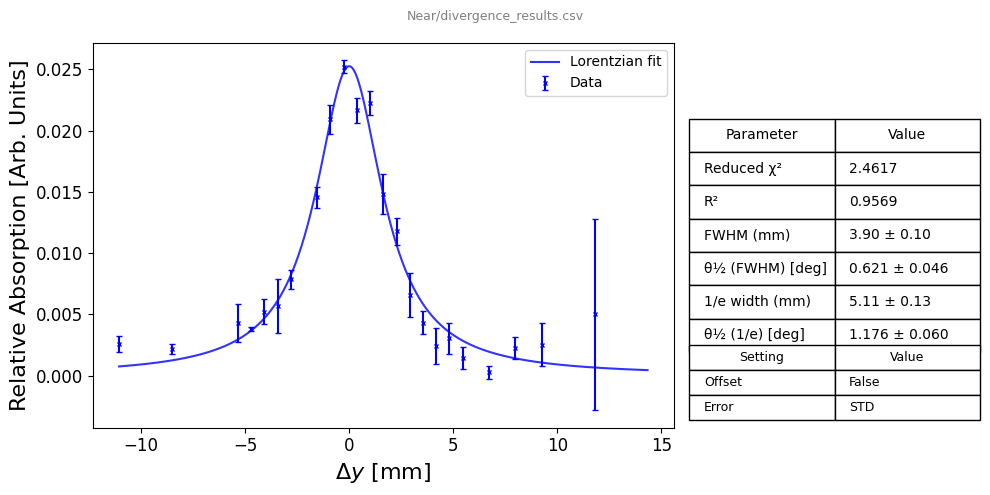

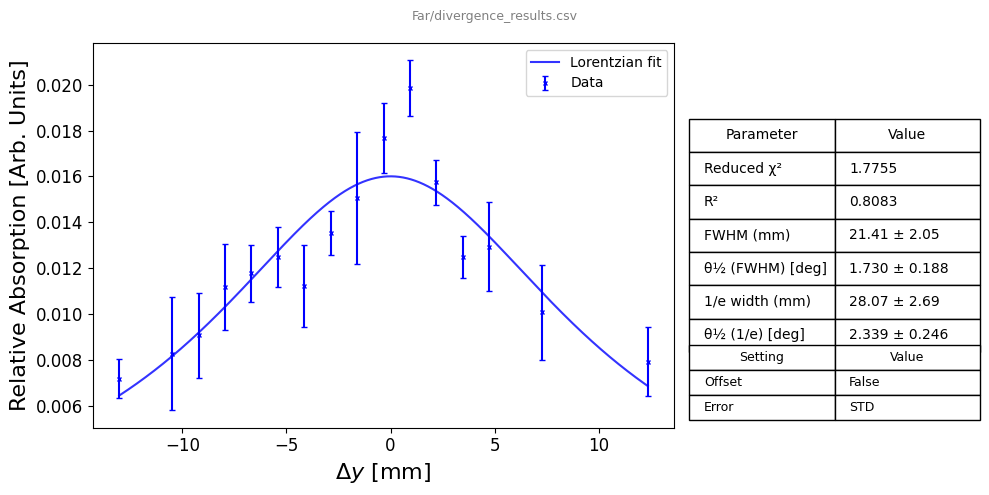

2.00694701021132
2.629999124607807


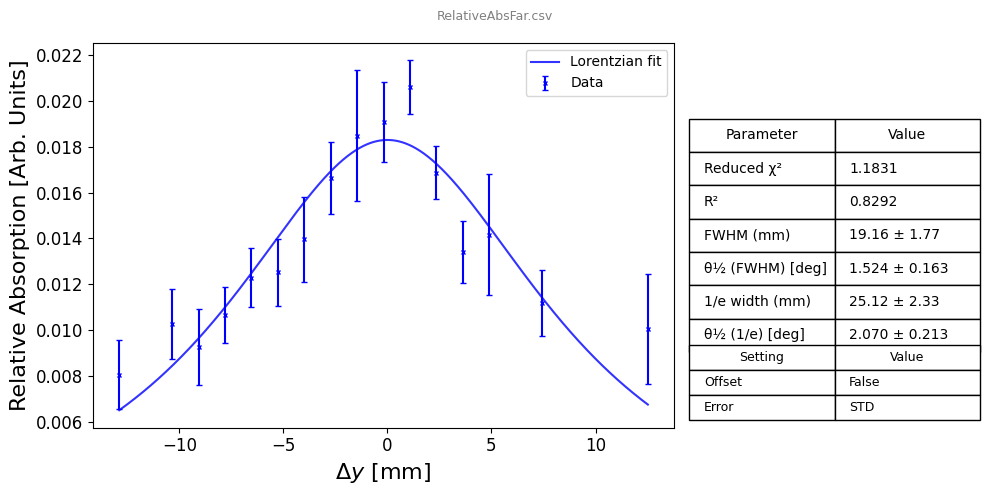

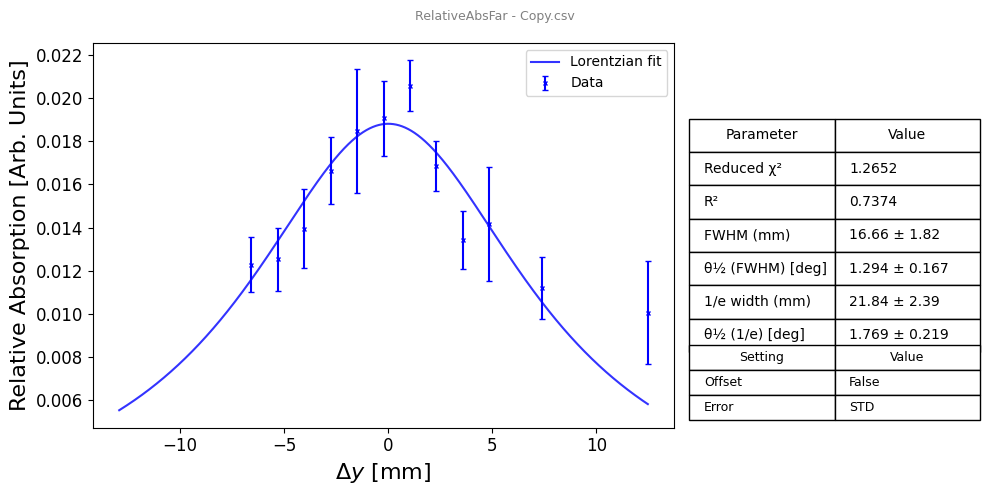

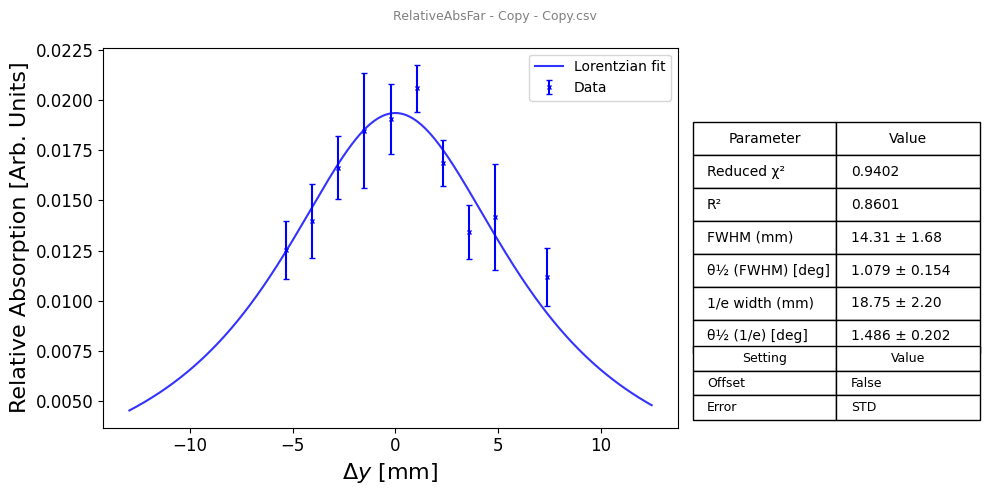

In [13]:
results_folder = "results/results_101225"

# get divergence 

div_results = divergence_fitting(results_folder, "Near/divergence_results.csv", offset= False, error="STD", plot=True)

FWHM1 = div_results["FWHM"]
ew1 = div_results["width_1e"]


div_results = divergence_fitting(results_folder, "Far/divergence_results.csv", offset= False, error="STD", plot=True, distancenozzle=12.3)

FWHM2 = div_results["FWHM"]
ew2 = div_results["width_1e"]

print(math.atan(((FWHM2-FWHM1)/2)/((12.3-2.46)*25.4))*180/math.pi)
print(math.atan(((ew2-ew1)/2)/((12.3-2.46)*25.4))*180/math.pi)



div_results = divergence_fitting(results_folder, "RelativeAbsFar.csv", offset= False, error="STD", plot=True, distancenozzle=12.3)
div_results = divergence_fitting(results_folder, "RelativeAbsFar - Copy.csv", offset= False, error="STD", plot=True, distancenozzle=12.3)
div_results = divergence_fitting(results_folder, "RelativeAbsFar - Copy - Copy.csv", offset= False, error="STD", plot=True, distancenozzle=12.3)


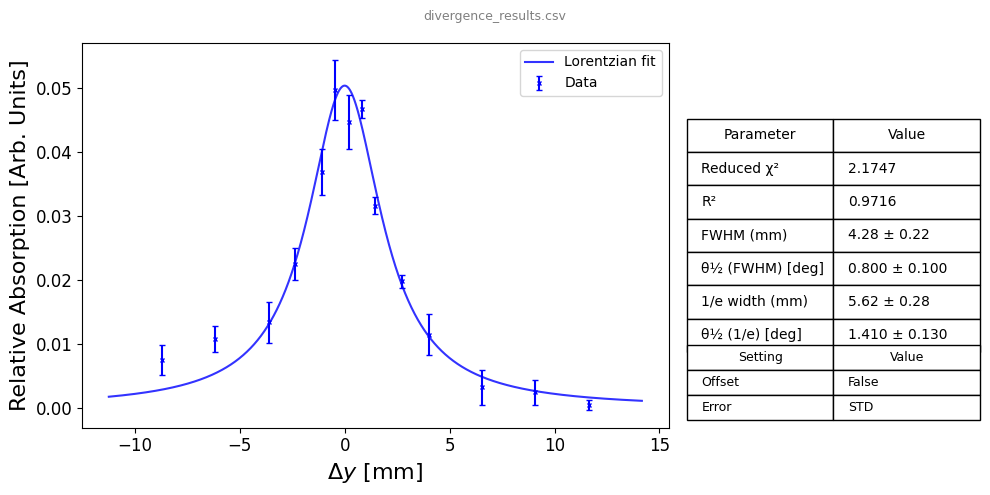

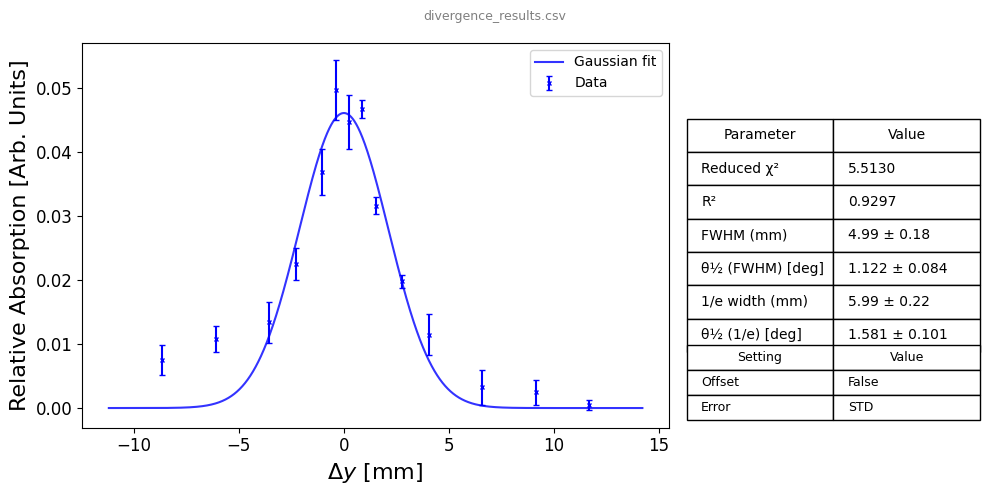

In [17]:
results_folder = "results/results_112825"

# get divergence 
div_results = divergence_fitting_lor(results_folder, "divergence_results.csv", offset= False, error="STD", plot=True)

div_results = divergence_fitting_gaus(results_folder, "divergence_results.csv", offset= False, error="STD", plot=True)

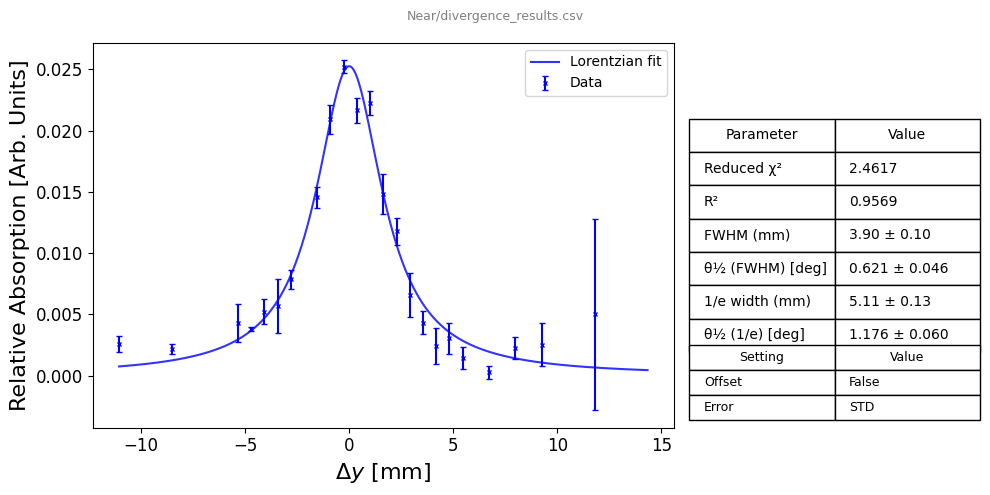

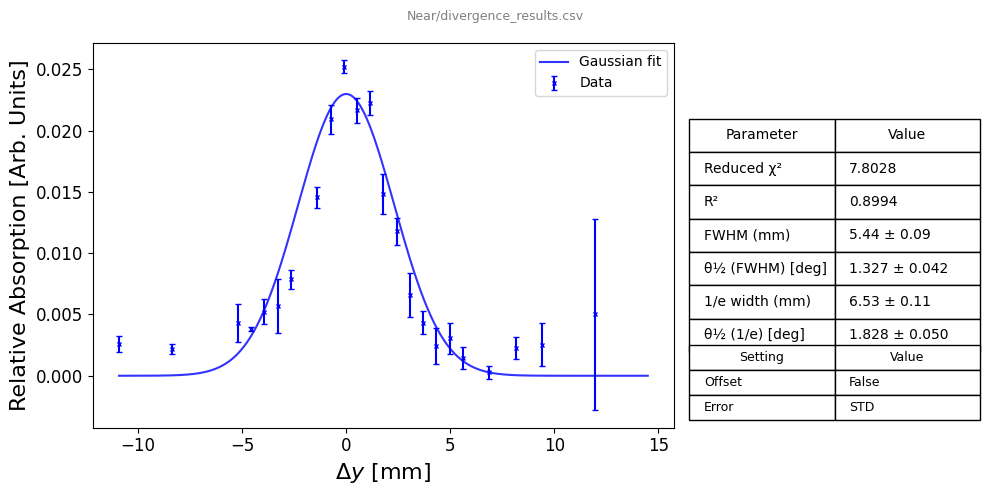

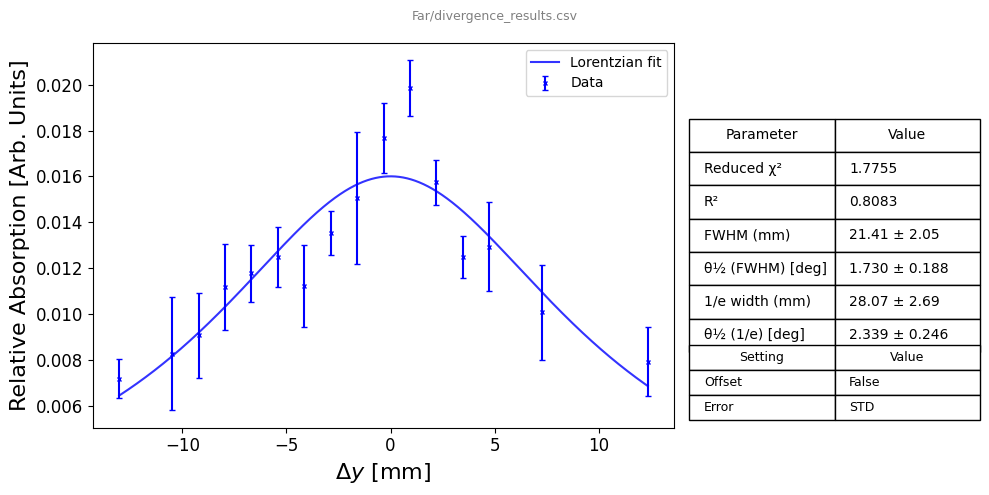

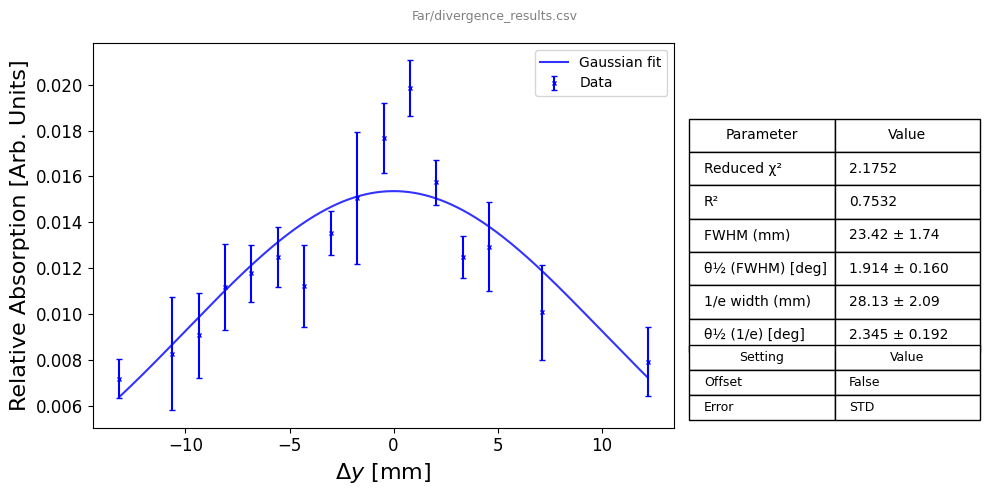

In [18]:
results_folder = "results/results_101225"

# get divergence 

div_results = divergence_fitting_lor(results_folder, "Near/divergence_results.csv", offset= False, error="STD", plot=True)
div_results = divergence_fitting_gaus(results_folder, "Near/divergence_results.csv", offset= False, error="STD", plot=True)

div_results = divergence_fitting_lor(results_folder, "Far/divergence_results.csv", offset= False, error="STD", plot=True, distancenozzle=12.3)
div_results = divergence_fitting_gaus(results_folder, "Far/divergence_results.csv", offset= False, error="STD", plot=True, distancenozzle=12.3)